# Working with Spatial Data in Python — Vector Data
**John Fay · Fall 2026**  


## Highlights

- Vector data represent spatial features as **geometries**: points, lines, and polygons.
  - *Point* = single coordinate pair
  - *Line* = sequence of coordinate pairs
  - *Polygon* = sequence of coordinate pairs, with the last overlapping the first.
- Geometries are stored as coordinate pairs in their own column in a **GeoDataFrame**.
- Geometries and spatial dataframes are also associated with a **coordinate reference system** (crs)
  - The crs defines origin and axes to which the coordinate pairs are referenced.
  - A crs can be geographic and use angular units (e.g. latitude/longitude) ;\
    Or it can be projected and use linear units (e.g. UTM, State Plane)

By the end, you should be able to create points from a table, inspect their CRS, display an interactive map, and attach county attributes using a spatial join.

## 1. Prepare your environment and workspace
In a Miniforge terminal, create an environment once:
```bash
conda create -n env700-vector -c conda-forge python=3.12 geopandas pandas matplotlib folium mapclassify jupyterlab ipykernel
conda activate env700-vector
```
Open this notebook in VS Code and select **Python (env700-vector)** using **Select Kernel**. 


In [1]:
#Packages for working with data files/remote data
from pathlib import Path
from urllib.request import urlopen
import platform

#Packages for working with data
import pandas as pd
import geopandas as gpd

#Packages for viewing data
import matplotlib.pyplot as plt
import folium
from IPython.display import display

### Locate the project folders
`pathlib.Path` replaces R's `here` and `fs` path operations. The next cell searches the current working directory and its parents for `Data/raw` or `.git`. If needed, set `PROJECT_ROOT` to your project folder explicitly. Relative paths are resolved from the kernel's working directory, which may differ from the notebook folder.

In [2]:
#Paths
PROJECT_ROOT = Path.cwd().parent
raw_folder = PROJECT_ROOT / "Data" / "raw"
processed_folder = PROJECT_ROOT / "Data" / "processed"
print("Project folder:", PROJECT_ROOT)
print("Raw data folder:", raw_folder)

Project folder: c:\Workspace\Teaching_F26\SampleCode
Raw data folder: c:\Workspace\Teaching_F26\SampleCode\Data\raw


### Optional: locate Box Drive
This mirrors the source lesson's platform-specific Box paths. These are candidate locations only; installations may use a different folder. The rest of the notebook uses the project folders above and does not require Box.

In [3]:
system = platform.system()
if system == "Darwin":
    box_path = Path.home() / "Library" / "CloudStorage" / "Box-Box"
elif system == "Windows":
    box_path = Path.home() / "Box"
else:
    box_path = None

if box_path is None:
    print("No Box Drive path configured for this operating system.")
else:
    print("Candidate Box path:", box_path)
    print("Folder exists:", box_path.exists())

Candidate Box path: C:\Users\jpfay\Box
Folder exists: True


## 2. Reading in spatial Data

### 2.1 Converting a dataframe with coordinate data into a GeoDataFrame
If your dataframe has coordinate data, i.e., columns for X and Y coordinates, you can create a column of geospatial point objects, called a **GeoSeries**, from these coordiate column using GeoPandas' `points_from_xy()` function. Once created, we create a GeoPandas GeoDataFrame from our original dataframe along with this GeoSeries object

Here we read in the `NWIS_SiteInfo_NE_RAW.csv` file, which has an "x" (`dec_long_va`) and a "y" (`dec_lat_va`) column. We then create the GeoSeries object from these coordinatge columns, and from that construct our GeoDataFrame via GeoPandas' `GeoDataFrame()` function.

Note we have to also provide the coordinate reference system (crs). We do so by providing its EPSG code; our data has coordinates that are latitude/longitude, so we use the EPSG code of 4326 which represents the World Geodetic Survey of 1984. (See <https://epsg.io/>).

### 2.1 Read the NWIS site table with Pandas. 

In [4]:
#Set the filename
NWIS_filename = raw_folder / "NWIS_SiteInfo_NE_RAW.csv"

#Read the file into a dataframe
NWIS_df = pd.read_csv(NWIS_filename, dtype={"site_no": "string"})

#Display
NWIS_df.head()

,site_no,station_nm,site_tp_cd,dec_lat_va,dec_long_va,coord_acy_cd,dec_coord_datum_cd
0,06453600,"Ponca Creek at Verdel, Nebr.",ST,42.811111,-98.175833,S,NAD83
1,06454100,"Niobrara River at Agate, Nebr.",ST,42.423611,-103.792222,S,NAD83
2,06461500,"Niobrara River near Sparks, Nebr.",ST,42.902222,-100.362222,S,NAD83
3,06463500,"Long Pine Creek near Riverview, Nebr.",ST,42.689444,-99.678889,S,NAD83
4,06463720,"Niobrara River at Mariaville, Nebr.",ST,42.780556,-99.339722,S,NAD83


In [10]:
#Create the GeoSeries object from the coordinate columns
the_geoseries = gpd.points_from_xy(
        x= NWIS_df["dec_long_va"], 
        y= NWIS_df["dec_lat_va"]
    )

#Construct a geodataframe from the dataframe and geoseries, specifying the crs
NWIS_gdf = gpd.GeoDataFrame(
    data = NWIS_df,
    geometry= the_geoseries,
    crs="EPSG:4326"
)

#Display
NWIS_gdf.head()

,site_no,station_nm,site_tp_cd,dec_lat_va,dec_long_va,coord_acy_cd,dec_coord_datum_cd,geometry
0,06453600,"Ponca Creek at Verdel, Nebr.",ST,42.811111,-98.175833,S,NAD83,POINT (-98.17583 42.81111)
1,06454100,"Niobrara River at Agate, Nebr.",ST,42.423611,-103.792222,S,NAD83,POINT (-103.79222 42.42361)
2,06461500,"Niobrara River near Sparks, Nebr.",ST,42.902222,-100.362222,S,NAD83,POINT (-100.36222 42.90222)
3,06463500,"Long Pine Creek near Riverview, Nebr.",ST,42.689444,-99.678889,S,NAD83,POINT (-99.67889 42.68944)
4,06463720,"Niobrara River at Mariaville, Nebr.",ST,42.780556,-99.339722,S,NAD83,POINT (-99.33972 42.78056)


### 2.3 Viewing GeoDataFrames

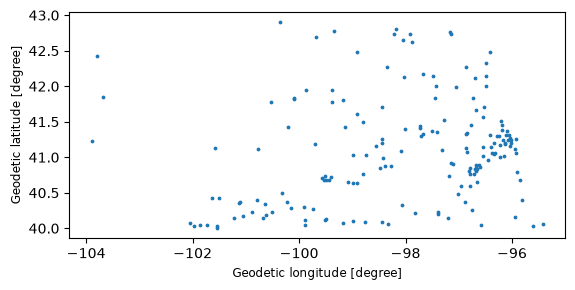

In [11]:
#View as a simple static map
simple_map = NWIS_gdf.plot(markersize=3)
simple_map;

In [ ]:
#View as an interactive map (requires internet connection)
NWIS_gdf.explore(tiles="OpenStreetMap")

### 2.3 Reading GeoJSON files directly from the internet

GeoJSON is a text file format that stores all the information of a geospatial feature class: geometries, attributes, and coordinate reference system information. The are text based equivalents of Shapefiles, but since they have all the data in a single file, they are a bit easier to work with. In fact, a web site can host these data on-line and we can read them directly into a spatial dataframe using `st_read()`.

A quick web search for "US Counties GeoJSON" reveals many sources of that dataset. The one that pop up in the result for me is: <https://eric.clst.org/tech/usgeojson/> - an individual who has decided to host many datasets on his personal web site.

The link for US Counties at a 1:5m scale is: [`https://eric.clst.org/assets/wiki/uploads/Stuff/gz_2010_us_050_00_5m.json`](https://eric.clst.org/assets/wiki/uploads/Stuff/gz_2010_us_050_00_5m.json).

We'll fetch that, reading its contents into a spatial dataframe, filtering for just counties in Nebraska, whose state FIPS code is "31".

In [7]:
#Set the URL
counties_url = "https://eric.clst.org/assets/wiki/uploads/Stuff/gz_2010_us_050_00_5m.json"

#Fetch as a geodataframe
counties_gdf = gpd.read_file(counties_url,encoding="ISO-8859-1")

#Subset for Nebraska (FIPS = 31)
counties_gdf = counties_gdf.loc[counties_gdf['STATE']=='31'].reset_index()

#Display
counties_gdf.head()

,index,GEO_ID,STATE,COUNTY,NAME,LSAD,CENSUSAREA,geometry
0,444,0500000US31001,31,001,Adams,County,563.272,"POLYGON ((-98.28285 40.69828, -98.2781 40.6982..."
1,445,0500000US31005,31,005,Arthur,County,715.355,"POLYGON ((-101.98463 41.39471, -101.98552 41.7..."
2,446,0500000US31009,31,009,Blaine,County,710.874,"POLYGON ((-99.68683 41.74033, -100.00041 41.73..."
3,447,0500000US31017,31,017,Brown,County,1221.333,"POLYGON ((-100.1676 42.08585, -100.16754 42.43..."
4,448,0500000US31029,31,029,Chase,County,894.419,"POLYGON ((-101.34536 40.69809, -101.34279 40.3..."


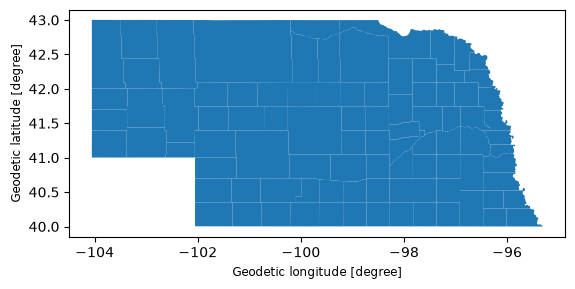

In [8]:
#Show
counties_gdf.plot();

## 3. Spatial Operations

### 3.1 Spatial Join
A spatial join assigns values in one dataset based on its overlap with a second spatial dataset. For example, if we wanted to tag each of our NWIS points with the county in which it falls, we would spatially join the county data to the points. This is done via the GeoPandas `sjoin()` function.

In [14]:
#Spatiall join the county attributes to the NWIS points
NWIS_joined = gpd.sjoin(
    left_df = NWIS_gdf,
    right_df = counties_gdf,
    predicate='intersects'
)

#Display info on the result
NWIS_joined.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   site_no             175 non-null    string  
 1   station_nm          175 non-null    str     
 2   site_tp_cd          175 non-null    str     
 3   dec_lat_va          175 non-null    float64 
 4   dec_long_va         175 non-null    float64 
 5   coord_acy_cd        175 non-null    str     
 6   dec_coord_datum_cd  175 non-null    str     
 7   geometry            175 non-null    geometry
 8   index_right0        175 non-null    int64   
 9   index               175 non-null    int64   
 10  GEO_ID              175 non-null    str     
 11  STATE               175 non-null    str     
 12  COUNTY              175 non-null    str     
 13  NAME                175 non-null    str     
 14  LSAD                175 non-null    str     
 15  CENSUSAREA          175 non-null

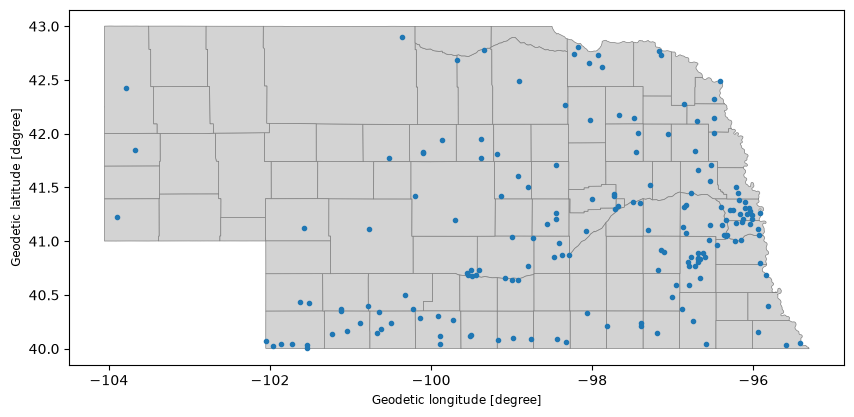

In [40]:
#Plot
base_map = counties_gdf.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6))
NWIS_joined.plot(ax=base_map,markersize=9);

### 3.2 Spaital Filtering
We can also select features in one spatial dataframe based on its relationship to features in another dataframe. This is analogous to creating a Boolean mask and then subsetting records where that mask is true.

First, we'll fetch some HUC (drainage area) data from https://data.openwaterfoundation.org/country/us/usgs/huc-basins/. Specifically, we'll get the Platte River HUC4 (1020): https://data.openwaterfoundation.org/country/us/usgs/huc-basins/huc4-basin-1020-platte.geojson

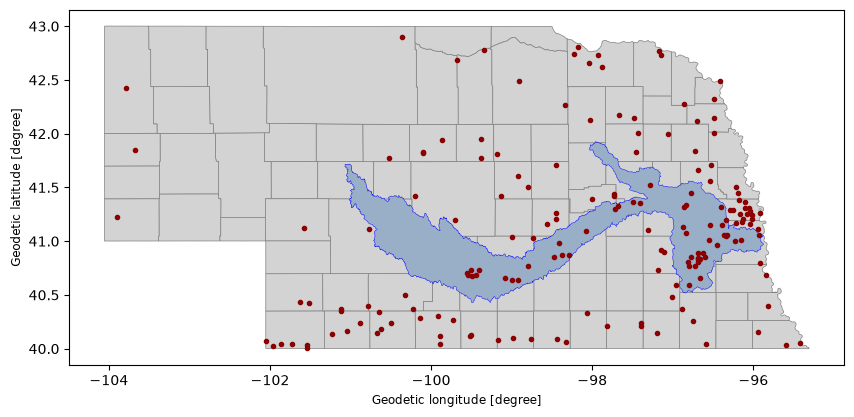

In [ ]:
#Fetch the North Platte HUC4 
huc4_url = 'https://data.openwaterfoundation.org/country/us/usgs/huc-basins/huc4-basin-1020-platte.geojson'
huc4_gdf = gpd.read_file(huc4_url) 

#Display the HUC4 with the NWIS points
base_map = counties_gdf.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6))
huc4_gdf.plot(ax=base_map,color='#98AFC7',linewidth=0.3,edgecolor='blue')
NWIS_joined.plot(ax=base_map,markersize=9,color='darkred');

Now, we'll filter the NWIS sites, selecting only those that intersect the features in the Platte River HUC4.

In [53]:
#Filter the NWIS sites that intersect the Platte River HUC4
NWIS_selected = NWIS_gdf[
    NWIS_gdf.intersects(huc4_gdf.geometry.union_all())
]
print(NWIS_selected.shape)

(50, 8)


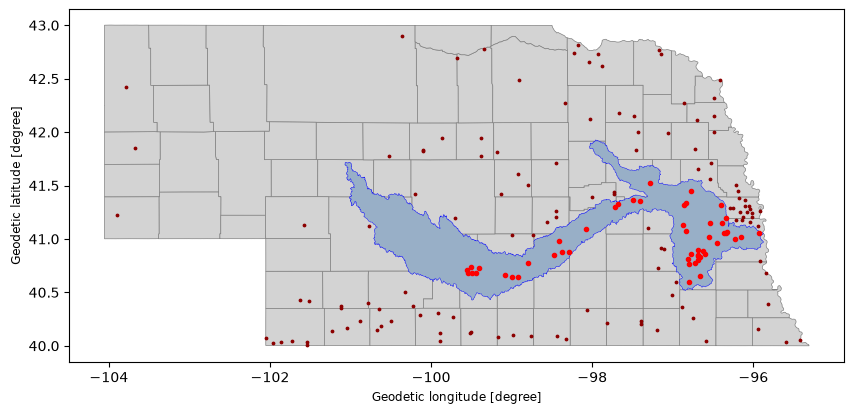

In [54]:
#Display
base_map = counties_gdf.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6))
huc4_gdf.plot(ax=base_map,color='#98AFC7',linewidth=0.3,edgecolor='blue')
NWIS_joined.plot(ax=base_map,markersize=3,color='darkred')
NWIS_selected.plot(ax=base_map,markersize=9,color='red');